# Advanced Stochastic Modeling: Lévy Processes, SPDEs, and Malliavin Calculus

This notebook provides a practical introduction to several advanced concepts in stochastic analysis. Since these topics are mathematically dense, we focus on **numerical simulations** and **intuitive use cases**.

## Table of Contents
1. [Lévy Processes](#levy)
2. [Stochastic Calculus (Itô SDE)](#stoch_calc)
3. [Stochastic Partial Differential Equations (SPDEs)](#spde)
4. [Introduction to Malliavin Calculus (Conceptual Numerical Approach)](#malliavin)

Select the project `.venv` Python kernel, then **Restart Kernel and Run All Cells**. Dependencies are listed in `requirements.txt`. Each example uses a fixed seed so it can be rerun reproducibly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

print("Dependencies loaded.")

Dependencies loaded.


<a id='levy'></a>
## 1. Lévy Processes

A Lévy process is a stochastic process with independent and stationary increments. The most famous example is Brownian Motion, but Lévy processes also allow for **jumps**.

**Use Case:** Modeling financial asset prices that experience sudden crashes (jump-diffusion models).

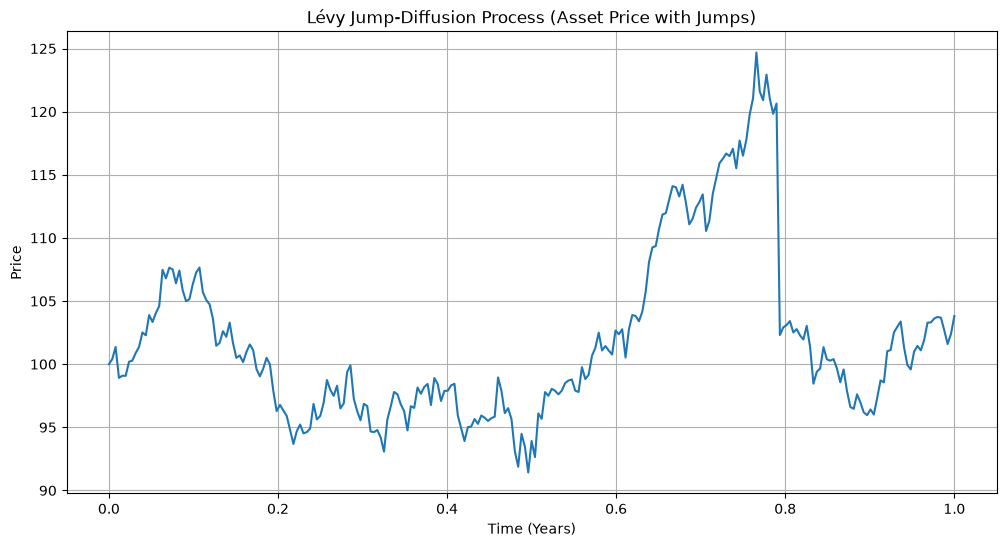

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_levy_jump_diffusion(S0, mu, sigma, lambda_jump, jump_mu, jump_sigma, T, N, seed=42):
    rng = np.random.default_rng(seed)
    dt = T / N
    t = np.linspace(0, T, N + 1)
    S = np.zeros(N + 1)
    S[0] = S0
    
    for i in range(1, N + 1):
        # Brownian component
        dW = rng.normal(0, np.sqrt(dt))
        
        # Jump component (Poisson process)
        num_jumps = rng.poisson(lambda_jump * dt)
        jump_sum = np.sum(rng.normal(jump_mu, jump_sigma, num_jumps)) if num_jumps > 0 else 0
        
        # Geometric Brownian Motion + Jumps
        S[i] = S[i-1] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * dW + jump_sum)
        
    return t, S

plt.figure(figsize=(12, 6))
t, S = simulate_levy_jump_diffusion(S0=100, mu=0.05, sigma=0.2, lambda_jump=2, jump_mu=-0.1, jump_sigma=0.1, T=1, N=252)
plt.plot(t, S)
plt.title("Lévy Jump-Diffusion Process (Asset Price with Jumps)")
plt.xlabel("Time (Years)")
plt.ylabel("Price")
plt.grid(True)
plt.show()

<a id='stoch_calc'></a>
## 2. Stochastic Calculus

The core of stochastic calculus is the **Itô Integral**. Unlike standard calculus, $df$ depends on $dt$ and $dW^2 = dt$ (the Itô Lemma).

**Use Case:** Solving the Black-Scholes equation or modeling interest rate dynamics.

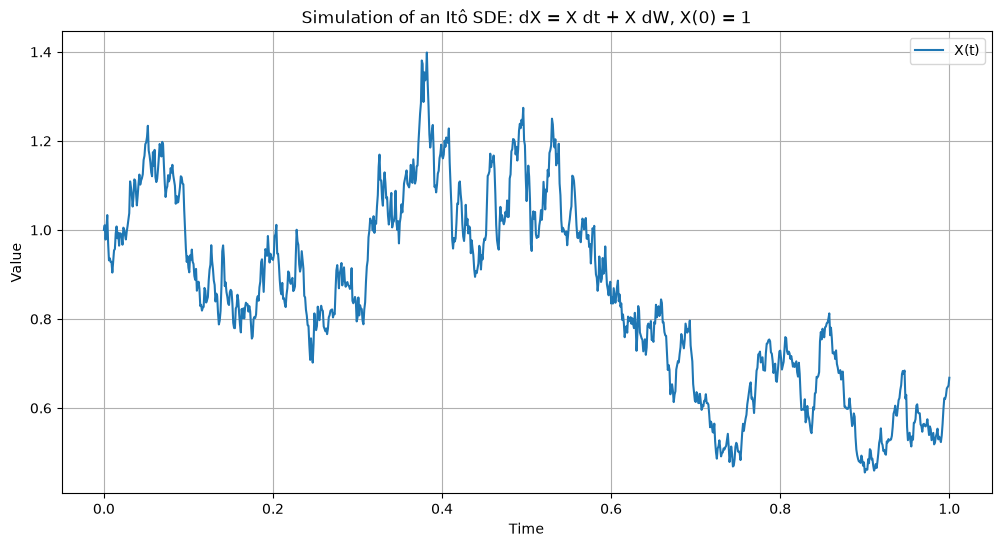

In [3]:
def simulate_ito_process(T=1.0, N=1000, seed=42):
    rng = np.random.default_rng(seed)
    dt = T / N
    W = np.zeros(N + 1)
    X = np.zeros(N + 1)
    X[0] = 1.0

    for i in range(1, N + 1):
        dW = rng.normal(0, np.sqrt(dt))
        W[i] = W[i - 1] + dW
        # Euler-Maruyama: use the same Brownian increment for W and X.
        X[i] = X[i - 1] + X[i - 1] * dt + X[i - 1] * dW

    return W, X

T_ito = 1.0
W, X = simulate_ito_process(T=T_ito)
t_ito = np.linspace(0, T_ito, len(X))
plt.figure(figsize=(12, 6))
plt.plot(t_ito, X, label="X(t)")
plt.title("Simulation of an Itô SDE: dX = X dt + X dW, X(0) = 1")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

<a id='spde'></a>
## 3. Stochastic Partial Differential Equations (SPDEs)

SPDEs add a noise term to a PDE. The most classic example is the **Stochastic Heat Equation**, used to model heat flow in a medium with random fluctuations.

**Use Case:** Modeling the growth of interfaces (KPZ equation) or noise in quantum fields.

This fixed-grid demonstration uses independent Brownian forcing at interior nodes and zero boundary values. The explicit diffusion step checks its stability limit before running.

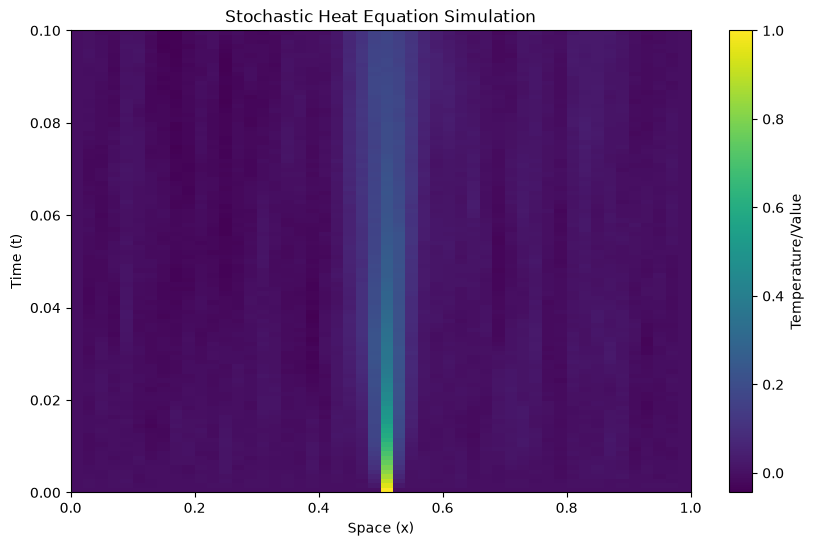

In [4]:
def simulate_stochastic_heat(L=1.0, T=0.1, Nx=50, Nt=100,
                             alpha=0.01, noise_std=0.1, seed=42):
    # Nx spatial grid points and Nt time intervals, including both endpoints.
    if Nx < 3 or Nt < 1 or L <= 0 or T <= 0 or alpha < 0 or noise_std < 0:
        raise ValueError("Require Nx >= 3, Nt >= 1, L/T > 0, and nonnegative alpha/noise_std.")
    dx = L / (Nx - 1)
    dt = T / Nt
    diffusion_ratio = alpha * dt / dx**2
    if diffusion_ratio > 0.5:
        raise ValueError("Unstable explicit heat step: increase Nt so alpha*dt/dx**2 <= 0.5.")

    rng = np.random.default_rng(seed)
    u = np.zeros((Nt + 1, Nx))
    u[0, Nx // 2] = 1.0

    for step in range(1, Nt + 1):
        previous = u[step - 1]
        laplacian = previous[2:] - 2 * previous[1:-1] + previous[:-2]
        # Independent Brownian forcing at each interior grid point.
        noise = noise_std * rng.normal(0, np.sqrt(dt), Nx - 2)
        u[step, 1:-1] = previous[1:-1] + diffusion_ratio * laplacian + noise
        # Endpoints remain zero (Dirichlet boundary conditions).

    return u

L_heat, T_heat = 1.0, 0.1
u_heat = simulate_stochastic_heat(L=L_heat, T=T_heat)
plt.figure(figsize=(10, 6))
plt.imshow(u_heat, aspect="auto", origin="lower",
           extent=[0, L_heat, 0, T_heat], cmap="viridis")
plt.colorbar(label="Temperature/Value")
plt.title("Stochastic Heat Equation Simulation")
plt.xlabel("Space (x)")
plt.ylabel("Time (t)")
plt.show()

<a id='malliavin'></a>
## 4. Malliavin Calculus (Conceptual)

Malliavin calculus is essentially "calculus of variations for stochastic processes." It allows us to take derivatives of random variables with respect to the underlying Brownian motion path.

**Use Case:** Calculating "Greeks" (sensitivities) in finance without needing the payoff function to be differentiable.

The example below is a finite-dimensional autograd illustration: it differentiates a sum of squared Gaussian inputs. It is a conceptual analogy, not an implementation of the full continuous-path calculus.

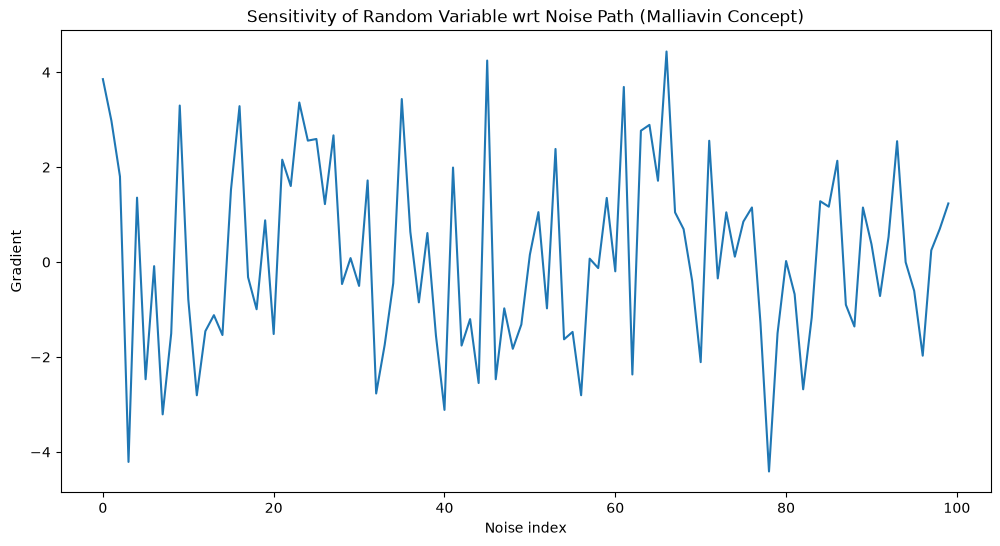

In [5]:
# We can use Autograd to illustrate a 'Malliavin-like' derivative
# by differentiating the output of a stochastic process wrt the noise input.

def malliavin_sensitivity(seed=42):
    generator = torch.Generator().manual_seed(seed)
    # Random noise (the path)
    dW = torch.randn(100, generator=generator, requires_grad=True)
    
    # A stochastic function: X = sum(W_i^2)
    X = torch.sum(dW**2)
    
    # Compute the gradient of the result wrt the noise
    X.backward()
    
    return dW.grad

grad = malliavin_sensitivity()
plt.figure(figsize=(12, 6))
plt.plot(grad.detach().numpy())
plt.title("Sensitivity of Random Variable wrt Noise Path (Malliavin Concept)")
plt.xlabel("Noise index")
plt.ylabel("Gradient")
plt.show()